# BBBC039 — Fluorescence Microscopy Image Analysis

## Source
[BBBC039 - cell nuclei](https://bbbc.broadinstitute.org/BBBC039?utm_source)

## Dataset: 
Broad Bioimage Benchmark Collection (BBBC039) — U2OS Cell Nuclei

## Objective: 
- Explore fluorescence microscopy images of stained cell nuclei
- Investigate pixel intensity distributions
- Develop methods for nuclear segmentation and quantitative analysis.

## Research question: 
Can we accurately identify, segment, and measure individual cell nuclei using computational image analysis?

---

### Inspect the raw image

In [3]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from skimage import io

In [4]:
# Path to a simple microscopy image
image_path = Path("../data/BBBC039-U20S_cell_nuclei/images/IXMtest_A02_s1_w1051DAA7C-7042-435F-99F0-1E847D9B42CB.tif")

In [5]:
# Load the image without modifying its pixel values
image = io.imread(image_path)

In [9]:
# Inspect image properties
print("Shape: ", image.shape)
print("Data type: ", image.dtype)
print("Minimum intensity: ", image.min())
print("Maximum intensity: ", image.max())
print(f"Mean intensity: {image.mean():.2f}")

Shape:  (520, 696)
Data type:  uint16
Minimum intensity:  120
Maximum intensity:  4095
Mean intensity: 248.14


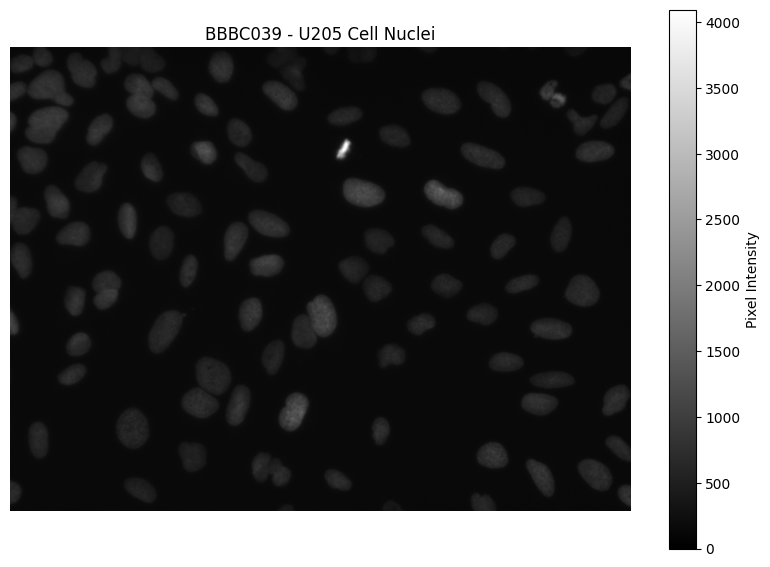

In [11]:
# Visualize the image
plt.figure(figsize=(10, 7))

plt.imshow(image, cmap="gray", vmin=0, vmax=4095)
plt.colorbar(label="Pixel Intensity")

plt.title("BBBC039 - U205 Cell Nuclei")
plt.axis("off")

plt.show()

I see a bunch of nuclei, a really bright spot and some overlapping.

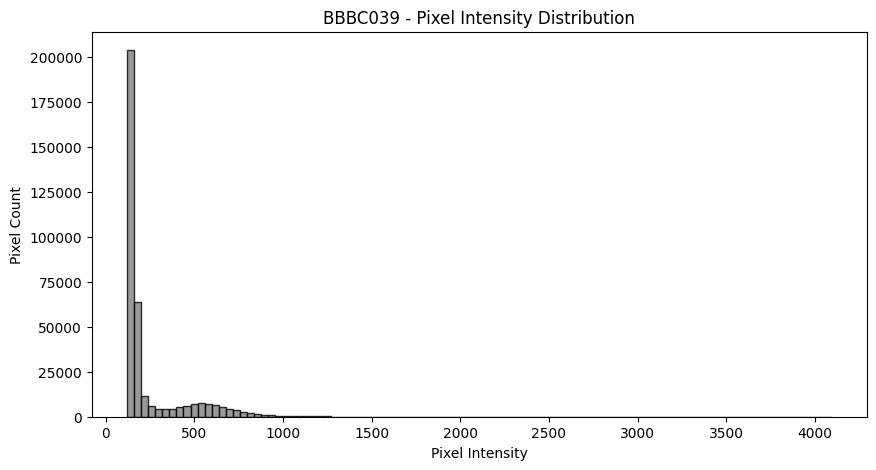

In [13]:
# How do the pixel intensities distribute across the image
plt.figure(figsize=(10,5))

plt.hist(
    image.ravel(), # flatten image into a one-dimensional array
    bins=100,
    color="gray",
    edgecolor="black",
    alpha=0.8
)

plt.title("BBBC039 - Pixel Intensity Distribution")
plt.xlabel("Pixel Intensity")
plt.ylabel("Pixel Count")

plt.show()

- The minimum intensity is 120, which is why it does not start at zero.
- It's right-skewed, with most intensities around 120 and ~250.  This makes sense, since the background is black.

In [14]:
# Otsu thresholding
from skimage.filters import threshold_otsu

# Calculate an automatic intensity threshold
otsu_threshold = threshold_otsu(image)

# Create a binary mask
binary_mask = image > otsu_threshold

print(f"Otsu threshold: {otsu_threshold}")
print(f"Foreground pixels: {binary_mask.sum():,}")
print(f"Foreground percentage: {binary_mask.mean() * 100:.2f}%")

Otsu threshold: 395
Foreground pixels: 64,349
Foreground percentage: 17.78%


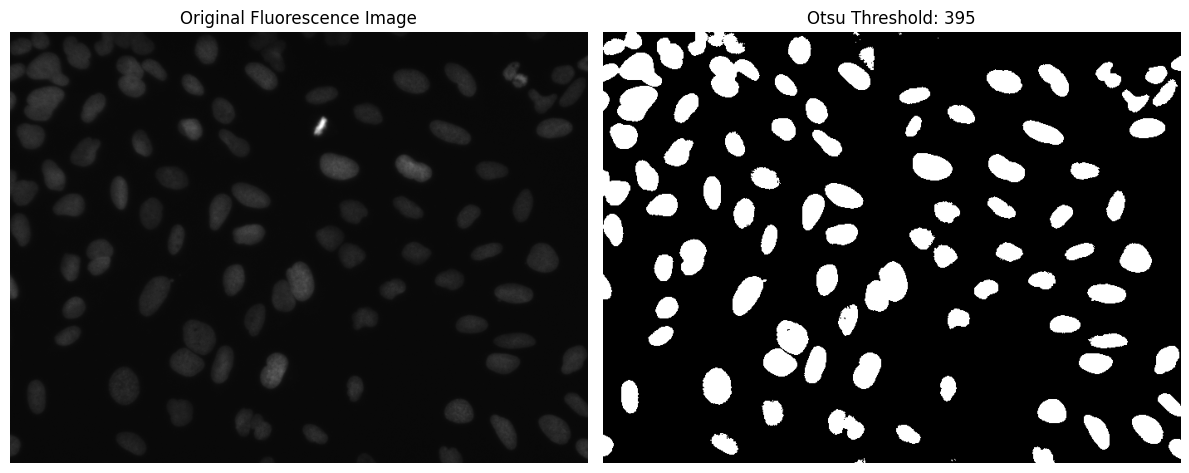

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(image, cmap="gray", vmin=0, vmax=4095)
axes[0].set_title("Original Fluorescence Image")
axes[0].axis("off")

axes[1].imshow(binary_mask, cmap="gray")
axes[1].set_title(f"Otsu Threshold: {otsu_threshold}")
axes[1].axis("off")

plt.tight_layout()
plt.show()

In [17]:
# Load the reference mask
mask_image_path = Path("../data/BBBC039-U20S_cell_nuclei/masks/IXMtest_A02_s1_w1051DAA7C-7042-435F-99F0-1E847D9B42CB.png")
reference_mask = io.imread(mask_image_path)

print("Shape: ", reference_mask.shape)
print("Data type: ", reference_mask.dtype)
print("Unique values: ", len(np.unique(reference_mask)))
print("Min: ", reference_mask.min())
print("Max: ", reference_mask.max())

Shape:  (520, 696, 4)
Data type:  uint8
Unique values:  5
Min:  0
Max:  255


Number of annotated nuclei: 110
Unique labels: 111


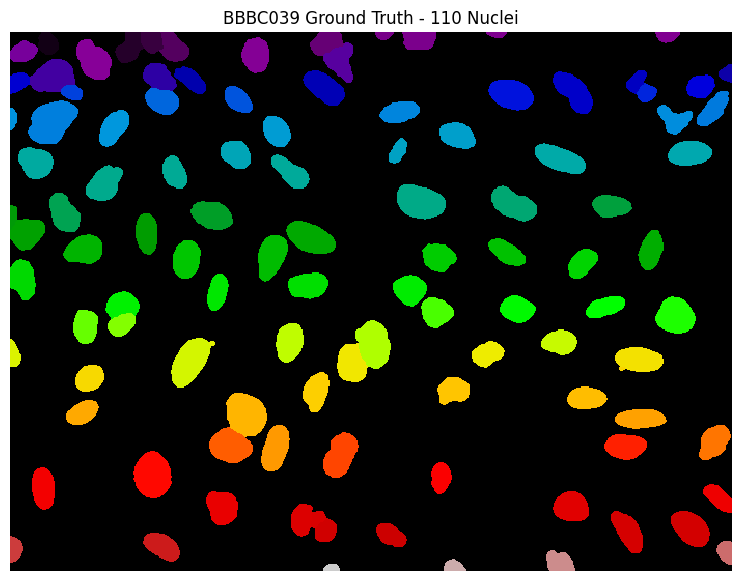

In [24]:
from skimage.measure import label

# Extract the encoded annotations
encoded_mask = reference_mask[:, :, 0]

# Assign unique IDs to connected regions of equal value
ground_truth = label(encoded_mask, background=0)

# Count annotated nuclei
n_nuclei = ground_truth.max()

print(f"Number of annotated nuclei: {n_nuclei}")
print(f"Unique labels: {len(np.unique(ground_truth))}")

# Visualize decoded instance labels
plt.figure(figsize=(10, 7))
plt.imshow(ground_truth, cmap="nipy_spectral", interpolation="nearest")
plt.title(f"BBBC039 Ground Truth - {n_nuclei} Nuclei")
plt.axis("off")
plt.show()


### Intersection over Union (IoU)

Intersection over Union (IoU) measures the overlap between two segmentation masks.

$$
IoU = \frac{|A \cap B|}{|A \cup B|}
$$

Where:
- **Intersection ($A \cap B$):** Pixels identified as nuclei by both masks.
- **Union ($A \cup B$):** Pixels identified as nuclei by either mask.
- **IoU = 1:** Perfect agreement.
- **IoU = 0:** No overlap.

IoU ranges from 0 to 1, with higher values indicating greater agreement between the predicted segmentation and the ground-truth mask.

In [25]:
# Convert ground truth instance labels to binary
gt_binary = ground_truth > 0

# Compare with Otsu segmentation
intersection = np.logical_and(gt_binary, binary_mask)
union = np.logical_or(gt_binary, binary_mask)

# Calculate Intersection over Union
iou = intersection.sum() / union.sum()

print(f"Intersection pixels: {intersection.sum():,}")
print(f"Union pixels: {union.sum():,}")
print(f"IoU: {iou:.4f}")

Intersection pixels: 63,658
Union pixels: 71,373
IoU: 0.8919


In [26]:
# Both masks identify the pixel as a nucleus
tp = np.count_nonzero(binary_mask & gt_binary)

# Otsu says nucleus, ground truth says background
fp = np.count_nonzero(binary_mask & ~gt_binary)

# Otsu says background, ground truth says nucleus
fn = np.count_nonzero(~binary_mask & gt_binary)

# Both masks identify the pixel as background
tn = np.count_nonzero(~binary_mask & ~gt_binary)

print(f"True Positives: {tp:,}")
print(f"False Positives: {fp:,}")
print(f"False Negatives: {fn:,}")
print(f"True Negatives: {tn:,}")

True Positives: 63,658
False Positives: 691
False Negatives: 7,024
True Negatives: 290,547


In [28]:
# Compare the original and lower thresholds
for threshold in [395, 350]:
    predicted = image > threshold

    tp = np.count_nonzero(predicted & gt_binary)
    fp = np.count_nonzero(predicted & ~gt_binary)
    fn = np.count_nonzero(~predicted & gt_binary)

    iou = tp / (tp + fp + fn)

    print(f"\nThreshold: {threshold}")
    print(f"True Positivies: {tp:,}")
    print(f"False Positives: {fp:,}")
    print(f"False Negatives: {fn:,}")
    print(f"IoU: {iou:.4f}")


Threshold: 395
True Positivies: 63,658
False Positives: 691
False Negatives: 7,024
IoU: 0.8919

Threshold: 350
True Positivies: 67,572
False Positives: 1,753
False Negatives: 3,110
IoU: 0.9329


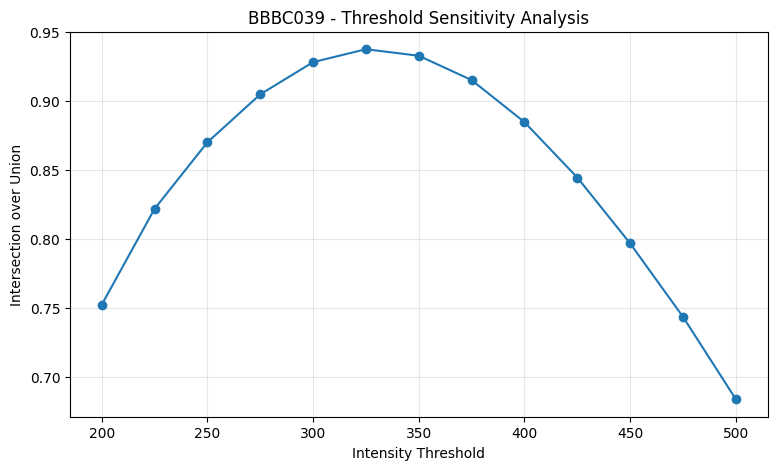

In [31]:
thresholds = range(200, 501, 25)
iou_scores = []

for threshold in thresholds:
    predicted = image > threshold

    tp = np.count_nonzero(predicted & gt_binary)
    fp = np.count_nonzero(predicted & ~gt_binary)
    fn = np.count_nonzero(~predicted & gt_binary)

    iou = tp / (tp + fp + fn)
    iou_scores.append(iou)

plt.figure(figsize=(9, 5))
plt.plot(thresholds, iou_scores, marker="o")

plt.xlabel("Intensity Threshold")
plt.ylabel("Intersection over Union")
plt.title("BBBC039 - Threshold Sensitivity Analysis")
plt.grid(alpha=0.3)

plt.show()

Ground truth nuclei: 110
Predicted connected regions: 97


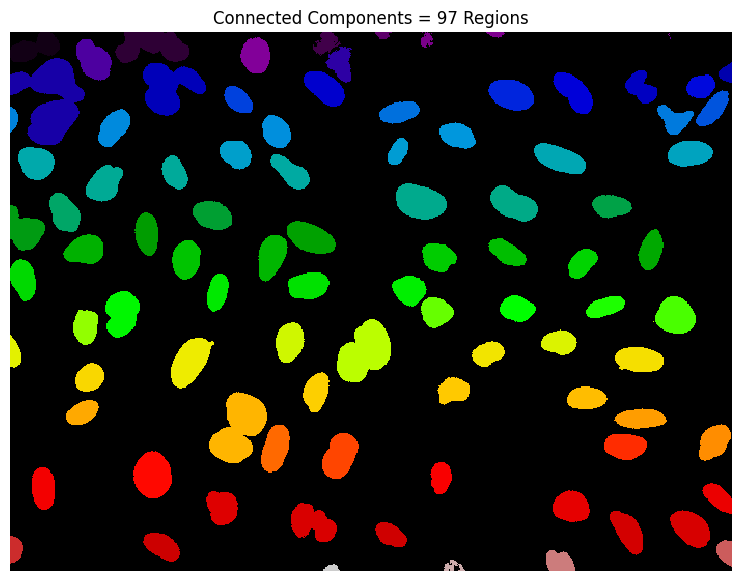

In [32]:
from skimage.measure import label

# Create binary mask using threshold 325
predicted_mask = image > 325

# Label connected foreground regions
# Connectivity =2 pixels considered connected through their edges or their corners
predicted_labels = label(predicted_mask, connectivity=2)

# Count the label regions
n_predicted = predicted_labels.max()

print(f"Ground truth nuclei: {n_nuclei}")
print(f"Predicted connected regions: {n_predicted}")

# Visualize labeled regions
plt.figure(figsize=(10, 7))
plt.imshow(predicted_labels, cmap="nipy_spectral", interpolation="nearest")
plt.title(f"Connected Components = {n_predicted} Regions")
plt.axis("off")
plt.show()

### Semantic Segmentation:
identifying nuclear pixels

### Instance Segmentation:
identifying each nucleus separately

Check whether some of the 97 regions are unusually large.

Because a connected region containing two merged nuclei will often have a larger area than a region containing just one nucleus.

Number of regions: 97
Smallest region: 1.0 pixels
Largest region: 3349.0 pixels
Mean region area: 741.20 pixels
Median region area: 706.00 pixels


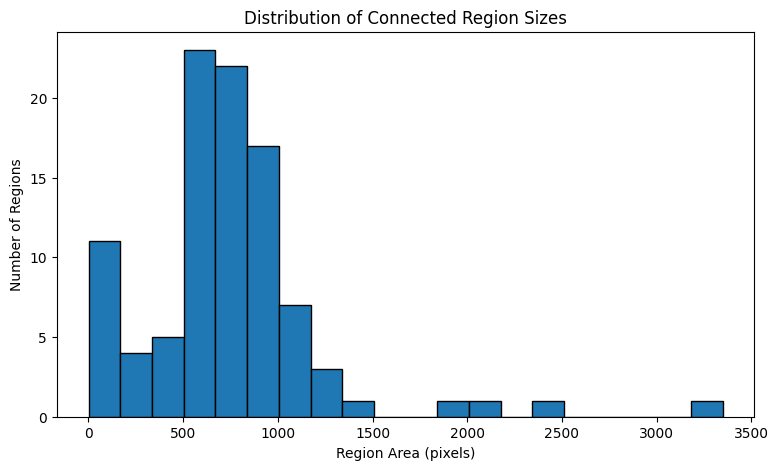

In [34]:
from skimage.measure import regionprops

regions = regionprops(predicted_labels)

# Extract the area of each connected region
areas = [region.area for region in regions]

print(f"Number of regions: {len(areas)}")
print(f"Smallest region: {min(areas)} pixels")
print(f"Largest region: {max(areas)} pixels")
print(f"Mean region area: {np.mean(areas):.2f} pixels")
print(f"Median region area: {np.median(areas):.2f} pixels")

plt.figure(figsize=(9,5))
plt.hist(areas, bins=20, edgecolor="black")
plt.xlabel("Region Area (pixels)")
plt.ylabel("Number of Regions")
plt.title("Distribution of Connected Region Sizes")
plt.show()
         

Let's look at some of the large outliers.

In [36]:
# Sort regions by area, largest first
largest_regions = sorted(
    regions,
    key = lambda region: region.area,
    reverse=True
)

# Inspect the five largest regions
for region in largest_regions[:5]:
    print(
        f"Label: {region.label}, "
        f"Area: {region.area} pixels, "
        f"Centroid: {region.centroid}" #geometric center of a region
    )

Label: 14, Area: 3349.0 pixels, Centroid: (65.25649447596298, 38.923260674828306)
Label: 75, Area: 2364.0 pixels, Centroid: (381.8599830795262, 220.4141285956007)
Label: 63, Area: 2123.0 pixels, Centroid: (308.42487046632124, 341.1983042863872)
Label: 16, Area: 1912.0 pixels, Centroid: (52.53870292887029, 152.92364016736403)
Label: 2, Area: 1501.0 pixels, Centroid: (13.27381745502998, 136.64890073284477)


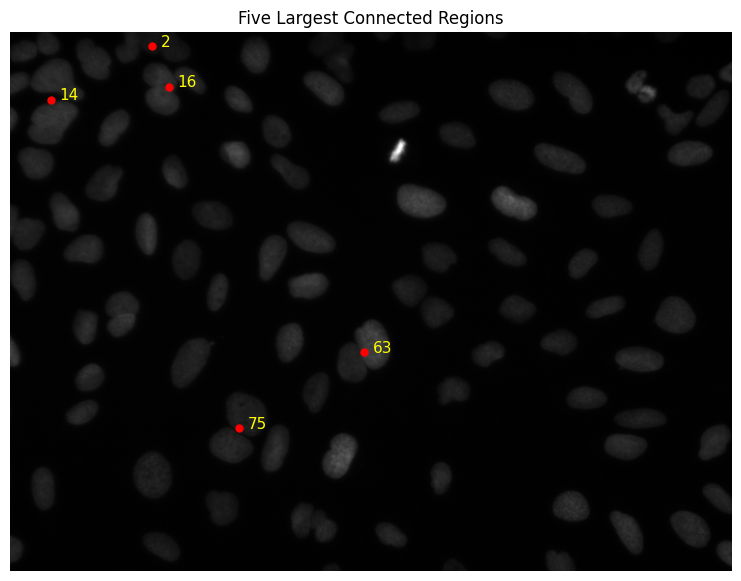

In [37]:
plt.figure(figsize=(10, 7))
plt.imshow(image, cmap="gray")

for region in largest_regions[:5]:
    row, col = region.centroid

    plt.plot(col, row, "ro", markersize=5)

    plt.text(col + 8, row, str(region.label), color="yellow", fontsize=11)

plt.title("Five Largest Connected Regions")
plt.axis("off")
plt.show()

Pretty cool, let's look at the borders since some of the overlaps are smaller than the largest ones.

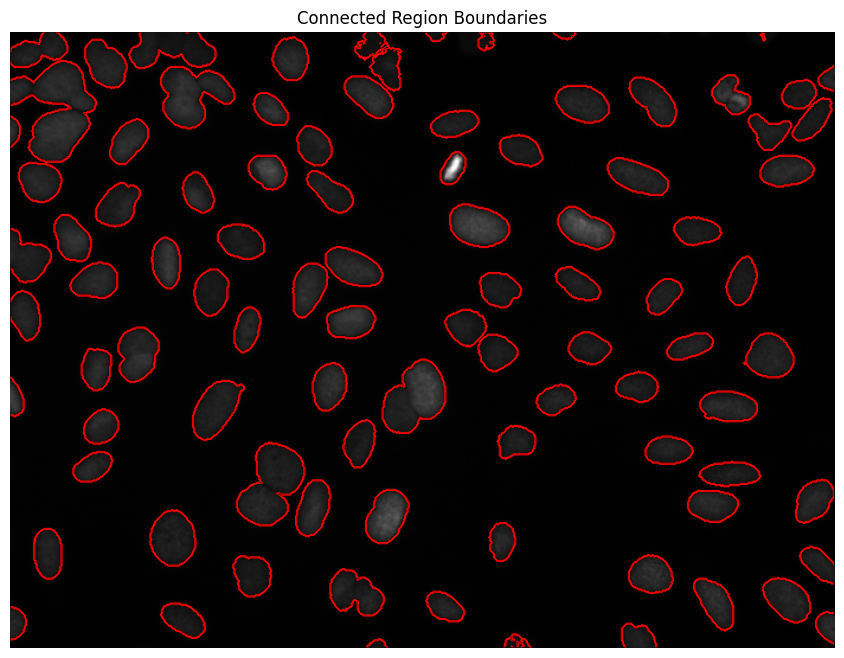

In [45]:
from skimage.segmentation import find_boundaries

# Find boundaries between labeled regions
boundaries = find_boundaries(predicted_labels, mode="outer")

plt.figure(figsize=(12, 8))
plt.imshow(image, cmap="gray")
plt.contour(boundaries, levels=[.5], colors="red", linewidths=0.7)

plt.title("Connected Region Boundaries")
plt.axis("off")
plt.show()

Several connected regions appear to contain more than one nucleus.

In [46]:
# Select the largest predicted region
region = largest_regions[0]

# Create a mask for this region
region_mask = predicted_labels == region.label

# Find ground-truth labels overlapping this region
overlapping_labels = np.unique(ground_truth[region_mask])

# Remove background label (0)
overlapping_labels = overlapping_labels[overlapping_labels != 0]

print(f"Predicted region: {region.label}")
print(f"Region area: {region.area} pixels")
print(f"Overlapping ground-truth nuclei: {overlapping_labels}")
print(f"Number of overlapping nuclei: {len(overlapping_labels)}")

Predicted region: 14
Region area: 3349.0 pixels
Overlapping ground-truth nuclei: [14 21 25 29]
Number of overlapping nuclei: 4


In [48]:
# Measure how many pixels it shares with each annotation
region = largest_regions[0]
region_mask = predicted_labels == region.label

for nucleus_id in overlapping_labels:
    overlap = np.count_nonzero(region_mask & (ground_truth == nucleus_id))

    nucleus_area = np.count_nonzero(ground_truth == nucleus_id)

    percentage = 100 * overlap / nucleus_area

    print(
        f"Nucleus {nucleus_id}: "
        f"{overlap:,} overlapping pixels "
        f"({percentage:.1f}% of nucleus)"
    )

Nucleus 14: 1,042 overlapping pixels (99.9% of nucleus)
Nucleus 21: 304 overlapping pixels (100.0% of nucleus)
Nucleus 25: 253 overlapping pixels (100.0% of nucleus)
Nucleus 29: 1,442 overlapping pixels (100.0% of nucleus)


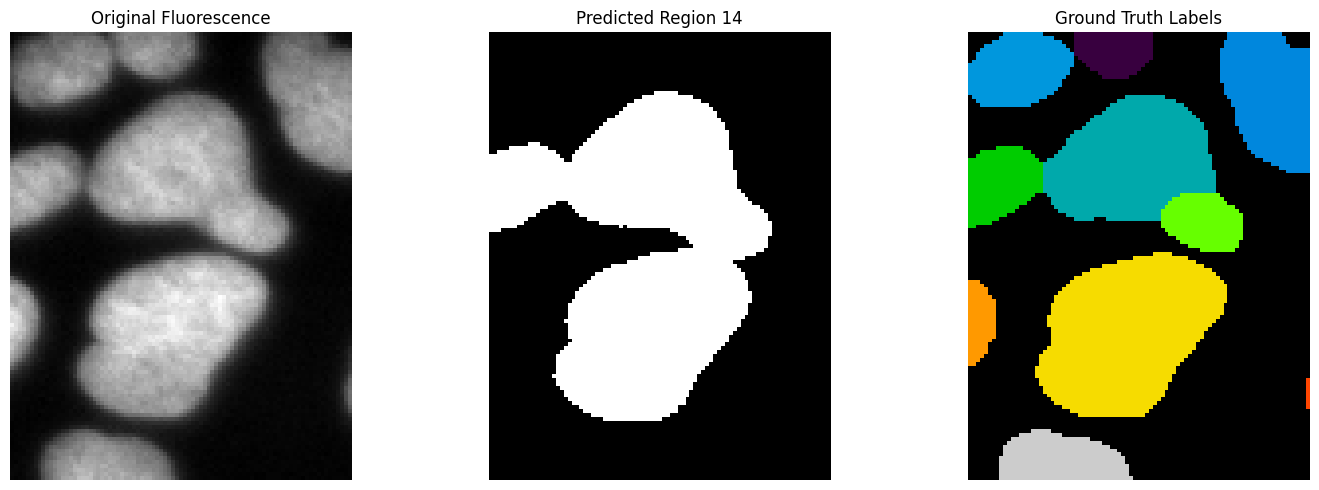

In [49]:
# Get the bounding box of region 14
region = largest_regions[0]
min_row, min_col, max_row, max_col = region.bbox

# Add padding
pad = 15

r1 = max(0, min_row - pad)
r2 = min(image.shape[0], max_row + pad)
c1 = max(0, min_col - pad)
c2 = min(image.shape[1], max_col + pad)

# Crop the same area from all three images
image_crop = image[r1:r2, c1:c2]
predicted_crop = predicted_labels[r1:r2, c1:c2]
ground_truth_crop = ground_truth[r1:r2, c1:c2]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(image_crop, cmap="gray")
axes[0].set_title("Original Fluorescence")

axes[1].imshow(predicted_crop == region.label, cmap="gray")
axes[1].set_title("Predicted Region 14")

axes[2].imshow(ground_truth_crop, cmap="nipy_spectral")
axes[2].set_title("Ground Truth Labels")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

- Original fluorescence: Several nuclear structures close together, with some touching.
- Predicted region 14: Thresholding and connected component labeling have merged them into a single white object.
- Ground truth: The annotations distinguish four nuclei within that predicted region.

### Watershed Segmentation
Watershed is an algorithm that can help separate touching objects by treating an image like a landscape.

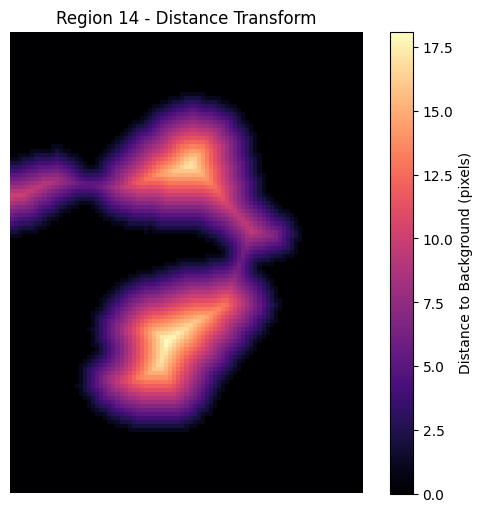

In [50]:
from scipy.ndimage import distance_transform_edt

# Use our cropped binary region
region_binary = predicted_crop == region.label

# Calculate distance from foreground to background
distance = distance_transform_edt(region_binary)

plt.figure(figsize=(7, 6))
plt.imshow(distance, cmap="magma")
plt.colorbar(label="Distance to Background (pixels)")
plt.title("Region 14 - Distance Transform")
plt.axis("off")
plt.show()